# Project 2: Physical Activity and Mental Health

**DATA 101 — Eidan Sigala**

**Research Question:** Do physically active adults report fewer poor mental health days than physically inactive adults?

This project uses data from the CDC's 2024 Behavioral Risk Factor Surveillance System (BRFSS) to examine the relationship between physical activity and the number of poor mental health days reported by adults.

The report is organized into four sections:

- A. Introduction
- B. Data Analysis & Statistical Inference
- C. Conclusion and Future Directions
- D. References

## A. Introduction

As someone who regularly goes to the gym and participates in martial arts, I was interested in exploring the relationship between physical activity and mental health. From my personal experience, exercising has helped improve my self-esteem and overall well-being. This made me curious about whether physically active adults report fewer poor mental health days than physically inactive adults.

For this project, I used the CDC's 2024 Behavioral Risk Factor Surveillance System (BRFSS) dataset. I chose this dataset because it contains information about both physical activity and poor mental health days, allowing me to apply what we learned in class to my research question. The variable `EXERANY2` identifies whether a respondent participated in leisure-time physical activity during the past 30 days, and `MENTHLTH` records the number of poor mental health days during that period. Self-esteem is my motivation for the topic, but it is not measured in this analysis.

## B. Data Analysis & Statistical Inference

### 1. Hypotheses

Let $\mu_{\mathrm{active}}$ and $\mu_{\mathrm{inactive}}$ represent the population mean number of poor mental health days in the two groups.

$$H_0: \mu_{\mathrm{active}} = \mu_{\mathrm{inactive}}$$

$$H_1: \mu_{\mathrm{active}} \ne \mu_{\mathrm{inactive}}$$

The null hypothesis states that there is no difference in the average number of poor mental health days between physically active and inactive adults. The alternative hypothesis states that there is a difference between the two groups.

I predict that physically active adults will report fewer poor mental health days than inactive adults. I used a significance level of 0.05 to determine whether the difference was statistically significant.

### 2. Setup and dataset loading

Run the code cells in order in Google Colab. Mount Google Drive, then load the complete XPT file from Drive. The uploaded notebook's successful import contains **457,670 rows and 301 columns**.

In [18]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
file_path = "/content/drive/MyDrive/LLCP2024.XPT"
df = pd.read_sas(file_path, format="xport")
print("Dataset shape:", df.shape)


Dataset shape: (457670, 301)


### 3. Select and inspect the variables

The initial comparison uses the exercise response and the number of poor mental health days. The survey-adjusted analysis later adds the weight, stratum, and primary sampling unit variables.

In [21]:
project_df = df[["EXERANY2", "MENTHLTH"]].copy()

In [22]:
project_df.head()
project_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457670 entries, 0 to 457669
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   EXERANY2  457667 non-null  float64
 1   MENTHLTH  457667 non-null  float64
dtypes: float64(2)
memory usage: 7.0 MB


In [23]:
# Display both response distributions before cleaning.
print("Exercise responses:")
print(project_df["EXERANY2"].value_counts(dropna=False))
print("\nMental health responses:")
print(project_df["MENTHLTH"].value_counts(dropna=False))

Exercise responses:
EXERANY2
1.0    350061
2.0    106294
7.0       860
9.0       452
NaN         3
Name: count, dtype: int64

Mental health responses:
MENTHLTH
88.0    269909
30.0     27295
2.0      25180
5.0      21369
10.0     16465
3.0      15961
1.0      15412
15.0     15317
20.0      9721
4.0       8381
7.0       8277
77.0      5594
25.0      3346
14.0      2847
99.0      2559
6.0       2374
8.0       1873
12.0      1334
28.0       932
21.0       549
29.0       491
18.0       347
9.0        332
16.0       297
17.0       291
27.0       236
13.0       187
22.0       186
11.0       145
24.0       134
23.0       132
26.0       123
19.0        71
NaN          3
Name: count, dtype: int64


### 4. Clean the responses

I kept exercise responses coded 1 (active) or 2 (inactive). In `MENTHLTH`, I replaced 88 with 0 because it means no poor mental health days. I removed codes 77 (don't know/not sure) and 99 (refused), along with missing mental health responses.

| Variable | Code | Meaning | Treatment |
|---|---|---|---|
| `EXERANY2` | 1 / 2 | Yes / No | Keep as the comparison groups |
| `EXERANY2` | 7 / 9 / missing | Unsure / refused / missing | Exclude |
| `MENTHLTH` | 88 | None | Recode to 0 |
| `MENTHLTH` | 77 / 99 / missing | Unsure / refused / missing | Exclude |



In [24]:
#Cleaning the dataset
#EXERANY2: 1 = Yes, 2 = No, 7 = Unsure, 9 = Refused
#MENTHTLH: 1-30 = Number of poor mental health days, 88 = None, 77 = Unsure, 99 = Refused

df_clean = project_df[project_df["EXERANY2"].isin([1, 2])].copy()

df_clean["MENTHLTH"] = df_clean["MENTHLTH"].replace({88: 0, 77: float("nan"), 99: float("nan")})
df_clean = df_clean.dropna(subset = ["MENTHLTH"])

df_clean.shape

(448418, 2)

### 5. Descriptive statistics and visualization

These averages describe the cleaned sample without survey weights.

In [25]:
#Comparing two groups
#1.0 = Physically Active Adults, 2.0 = Physically inactive adults

df_clean.groupby("EXERANY2")["MENTHLTH"].mean()

,MENTHLTH
EXERANY2,
1.0,3.910774
2.0,6.084912


The saved results are approximately **3.91 days for active adults** and **6.08 days for inactive adults**. The chart below uses these unweighted averages.

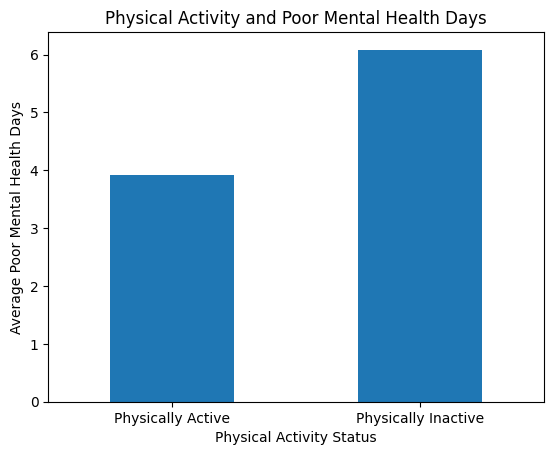

In [26]:
averages = df_clean.groupby("EXERANY2")["MENTHLTH"].mean()

averages.index = ["Physically Active", "Physically Inactive"]

averages.plot(kind="bar")

plt.title("Physical Activity and Poor Mental Health Days")
plt.xlabel("Physical Activity Status")
plt.ylabel("Average Poor Mental Health Days")
plt.xticks(rotation=0)
plt.show()

### 6. Preliminary unweighted t-test

The Welch two-sample t-test compares the average number of poor mental health days between physically active and inactive adults. This test uses unweighted data and does not account for the survey's sampling design, so it serves as a preliminary analysis.

In [27]:
#Statistical hypothesis test

from scipy.stats import ttest_ind

active = df_clean[df_clean["EXERANY2"] == 1.0]["MENTHLTH"]
inactive = df_clean[df_clean["EXERANY2"] == 2.0]["MENTHLTH"]

t_stat, p_value = ttest_ind(active, inactive, equal_var = False)


print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -64.09624722147348
P-value: 0.0


The saved output shows $t \approx -64.10$. Its displayed p-value of `0.0` reflects numerical precision; report it as **p < 0.001**, rather than claiming the probability is exactly zero.

### 7. Prepare the survey-adjusted analysis

Survey weights change how much each response contributes to the estimated population average. Strata and primary sampling units describe the sampling structure and are used to estimate uncertainty.

The following cells verify the five required columns, clean the survey data, remove missing design information, restrict poor mental health days to 0–30, and require positive weights.

| Column | Role |
|---|---|
| `EXERANY2` | Physical activity group |
| `MENTHLTH` | Poor mental health days |
| `_LLCPWT` | Survey weight |
| `_STSTR` | Sampling stratum |
| `_PSU` | Primary sampling unit |

In [28]:
df.shape
columns_needed = [
    "EXERANY2",
    "MENTHLTH",
    "_LLCPWT",
    "_STSTR",
    "_PSU"
]

for col in columns_needed:
    print(col, col in df.columns)

EXERANY2 True
MENTHLTH True
_LLCPWT True
_STSTR True
_PSU True


In [29]:
survey_df = df[
    ["EXERANY2", "MENTHLTH", "_LLCPWT", "_STSTR", "_PSU"]
].copy()

survey_df = survey_df[
    survey_df["EXERANY2"].isin([1, 2])
]

survey_df["MENTHLTH"] = survey_df["MENTHLTH"].replace({
    88: 0,
    77: np.nan,
    99: np.nan
})

survey_df = survey_df.dropna(
    subset=["MENTHLTH", "_LLCPWT", "_STSTR", "_PSU"]
)

survey_df = survey_df[
    (survey_df["MENTHLTH"].between(0, 30)) &
    (survey_df["_LLCPWT"] > 0)
]



### 8. Weighted group averages

To compare the two groups, I calculated the survey-weighted average number of poor mental health days reported by physically active and inactive adults. The survey weights help account for differences in how respondents were sampled.

In [30]:
for group in [1, 2]:
    subset = survey_df[survey_df["EXERANY2"] == group]

    weighted_mean = np.average(
        subset["MENTHLTH"],
        weights=subset["_LLCPWT"]
    )

    print(f"Group {group}: {weighted_mean:.4f} days")

Group 1: 4.4989 days
Group 2: 6.3166 days


The saved weighted averages are **4.4989 days for active adults** and **6.3166 days for inactive adults**, a difference of about **1.82 days (inactive minus active)**. These replace the older figures from the incomplete dataset.

### 9. Survey-adjusted t-test in R

Since the BRFSS dataset uses survey weights and a complex sampling design, I used the R `survey` package for my final statistical test. I referenced Allie Warren's Survey Analysis tutorial on GitHub to understand how to define a survey design using `svydesign()` and compare group means using `svyttest()`. This allowed me to account for the survey design rather than relying only on the regular Welch t-test.

In [31]:
!apt-get -qq update
!apt-get -qq install -y r-base r-cran-survey

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [32]:
survey_df.to_csv("survey_clean.csv", index=False)

In [33]:
%%writefile survey_test.R

library(survey)

df <- read.csv("survey_clean.csv")

# Rename survey variables
names(df)[names(df) == "X_PSU"] <- "PSU"
names(df)[names(df) == "X_STSTR"] <- "STSTR"
names(df)[names(df) == "X_LLCPWT"] <- "LLCPWT"

# Set up survey design
design <- svydesign(
  ids = ~PSU,
  strata = ~STSTR,
  weights = ~LLCPWT,
  data = df,
  nest = TRUE
)

# Handle strata containing only one PSU
options(survey.lonely.psu = "adjust")

# Perform survey-adjusted t-test
result <- svyttest(
  MENTHLTH ~ EXERANY2,
  design = design
)

print(result)

Overwriting survey_test.R


In [35]:
!Rscript survey_test.R

Loading required package: grid
Loading required package: Matrix
Loading required package: survival

Attaching package: ‘survey’

The following object is masked from ‘package:graphics’:

    dotchart


	Design-based t-test

data:  MENTHLTH ~ EXERANY2
t = 22.936, df = 446024, p-value < 2.2e-16
alternative hypothesis: true difference in mean is not equal to 0
95 percent confidence interval:
 1.662383 1.973041
sample estimates:
difference in mean 
          1.817712 



### 10. Final statistical interpretation

- Survey-adjusted t-statistic: **22.936**
- Degrees of freedom: **446,024**
- p-value: **< 2.2 x 10 ^ -16**
- Difference in Means: **1.82 days**
- 95% confidence interval: **1.66 to 1.97 days**
- Decision at $\alpha = 0.05$: **We reject the null hypothesis**

The survey-adjusted t-test resulted in a t-statistic of 22.936 with 446,024 degrees of freedom. The p-value was less than 0.001, which is below the significance level of 0.05. Therefore, I rejected the null hypothesis.

Physically inactive adults reported approximately 1.82 more poor mental health days than physically active adults, with a 95% confidence interval of 1.66 to 1.97 days. These results suggest a statistically significant association between physical activity and fewer poor mental health days, but they do not prove causation.

## C. Conclusion and Future Directions

My research examined whether physically active adults reported fewer poor mental health days compared to physically inactive adults. Using the CDC's 2024 BRFSS dataset, I found that physically active adults reported an average of 4.50 poor mental health days, while inactive adults reported an average of 6.32 days. This was a difference of approximately 1.82 days. The survey-adjusted t-test showed that this difference was statistically significant, with a p-value below 0.05. These results supported my original prediction that physically active adults would report fewer poor mental health days.

Although the results showed a relationship between physical activity and mental health, they do not necessarily prove that exercise directly causes better mental health. The survey relies on people's own responses, and other factors such as stress, physical health, and personal circumstances could influence the results. Personally, I believe that being physically active matters more than the specific type of exercise someone does. Whether it's walking, going to the gym, or participating in sports, I think getting some form of movement is what's important. In the future, I would be interested in researching whether even small amounts of physical activity are associated with better mental health. As someone who regularly exercises, I was interested in this topic because physical activity has helped improve my own self-esteem and overall well-being.

## D. References

Centers for Disease Control and Prevention. (2024). *Behavioral Risk Factor Surveillance System: 2024 annual survey data.* https://www.cdc.gov/brfss/annual_data/annual_2024.html

Warren, A. (2025, December 9). *Survey analysis* [Tutorial]. GitHub. https://github.com/WA-LHJ-Analytic-Resources/r-tutorials/blob/main/notebooks/survey_analysis.md